In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
import fspiderman as sp
from HItargets_utils import hi_planets_by_name

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("K2-141 b")
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = planet.args

fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# Geometric albedo in the optical from Zieba 2022 (using Kepler, Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate. Zieba 2022 assumed A_B=A for Kepler.
Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
# A_B basically unrelated to A (MIR band integrated), mainly influenced by albedo in optical (lambda_max=630nm) + clouds/atmosphere
A_B = 3/2 * Ag # 0.42
# More physical would be:
# A_B = 0.1 # typical lava world in optical (Essack 2020), probably slight underestimate for bolometric.
# A_B = q * f_red * Ag_opt # with q~0.6 (more realistic for e.g. moon, Mercury), and f_red a spectral correction factor.

# ASSUMPTION (!)
# Model for band-integrated albedo in MIRI/LRS band (MIR)
def A_model(A_B):
    # return A_B # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate). Also, A_LRS and A_B are basically unrelated since >99% of stellar flux is below 5um - same actually goes for Spitzer: 98% under 3.7um.
    return .1 # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR

A = A_model(A_B) #0.1

### Radiant Intensity Lightcurve

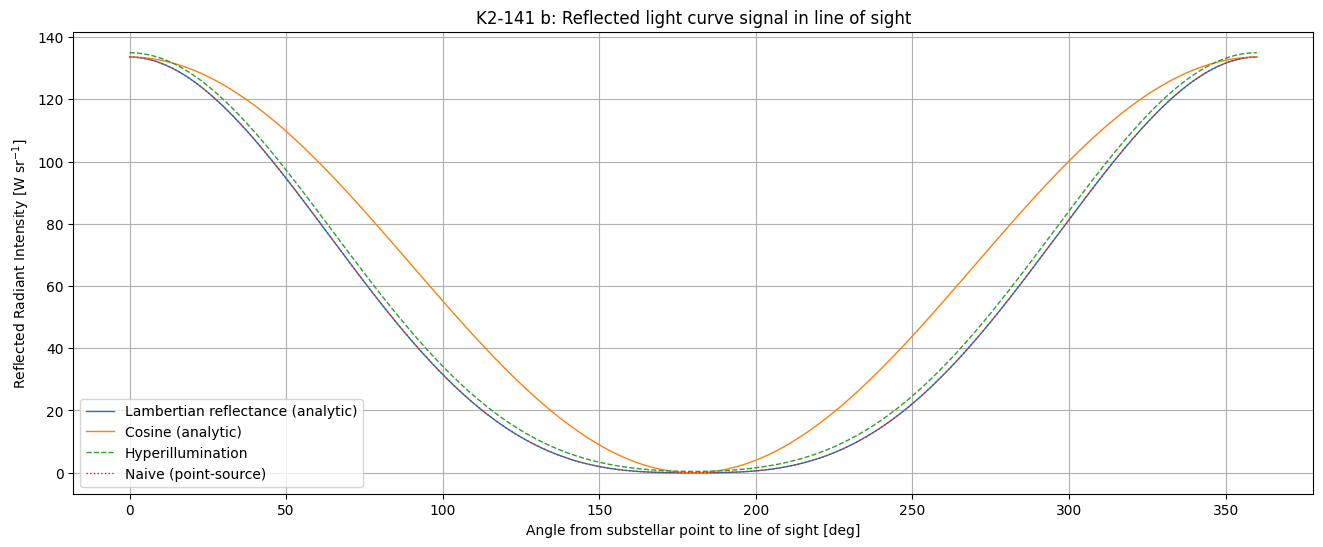

In [4]:
epsilon = np.linspace(0, 360, 1000)

L_hyperillum = reflected_lightcurve(np.radians(epsilon), planet, insolation_model="hyperillum", unit="radiant intensity", A=A, u_B=u_B)
L_naive = reflected_lightcurve(np.radians(epsilon), planet, insolation_model="naive", unit="radiant intensity", A=A, u_B=u_B)
L_cos = (np.cos(np.radians(epsilon))+1)/2*np.max(L_naive)
L_lambertian = lambertian_reflectance(np.radians(epsilon), planet, unit="radiant intensity", A=A)

plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_cos, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_hyperillum, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Radiant Intensity [W sr$^{-1}$]")
plt.title(f"{planet.name}: Reflected light curve signal in line of sight")
plt.legend()
plt.grid()

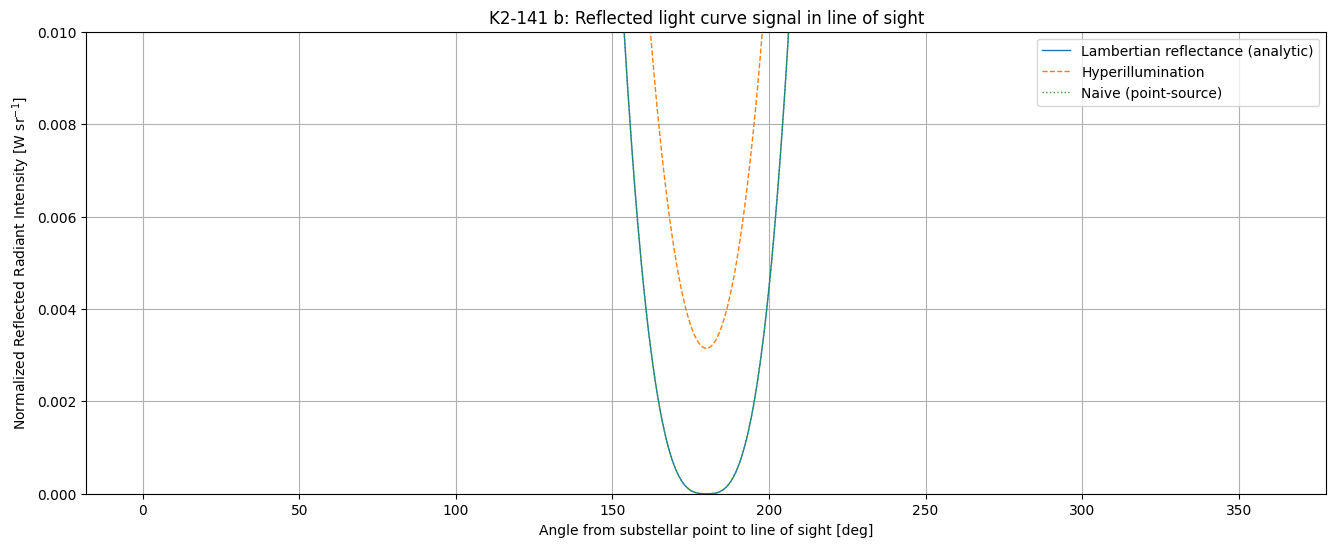

In [5]:
amp = np.max(L_lambertian)
plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian/amp, linewidth=1, label="Lambertian reflectance (analytic)")
#plt.plot(epsilon, L_cos/amp, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_hyperillum/amp, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive/amp, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Normalized Reflected Radiant Intensity [W sr$^{-1}$]")
plt.title(f"{planet.name}: Reflected light curve signal in line of sight")
plt.legend()
plt.ylim(0., 0.01)
plt.grid()

### Normalized Lightcurve Fp/Fs

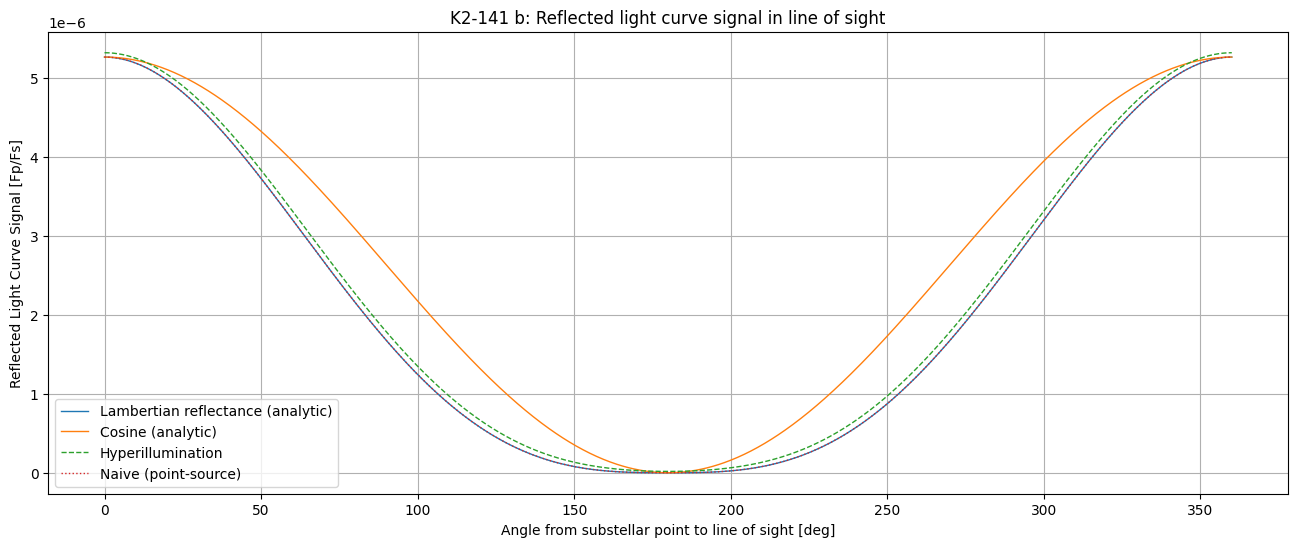

In [6]:
epsilon = np.linspace(0, 360, 1000)

L_hyperillum = reflected_lightcurve(np.radians(epsilon), planet, insolation_model="hyperillum", unit="normalized", A=A, u_B=u_B)
L_naive = reflected_lightcurve(np.radians(epsilon), planet, insolation_model="naive", unit="normalized", A=A, u_B=u_B)
L_cos = (np.cos(np.radians(epsilon))+1)/2*np.max(L_naive)
L_lambertian = lambertian_reflectance(np.radians(epsilon), planet, unit="normalized", A=A)

plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_cos, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_hyperillum, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Light Curve Signal [Fp/Fs]")
plt.title(f"{planet.name}: Reflected light curve signal in line of sight")
plt.legend()
plt.grid()

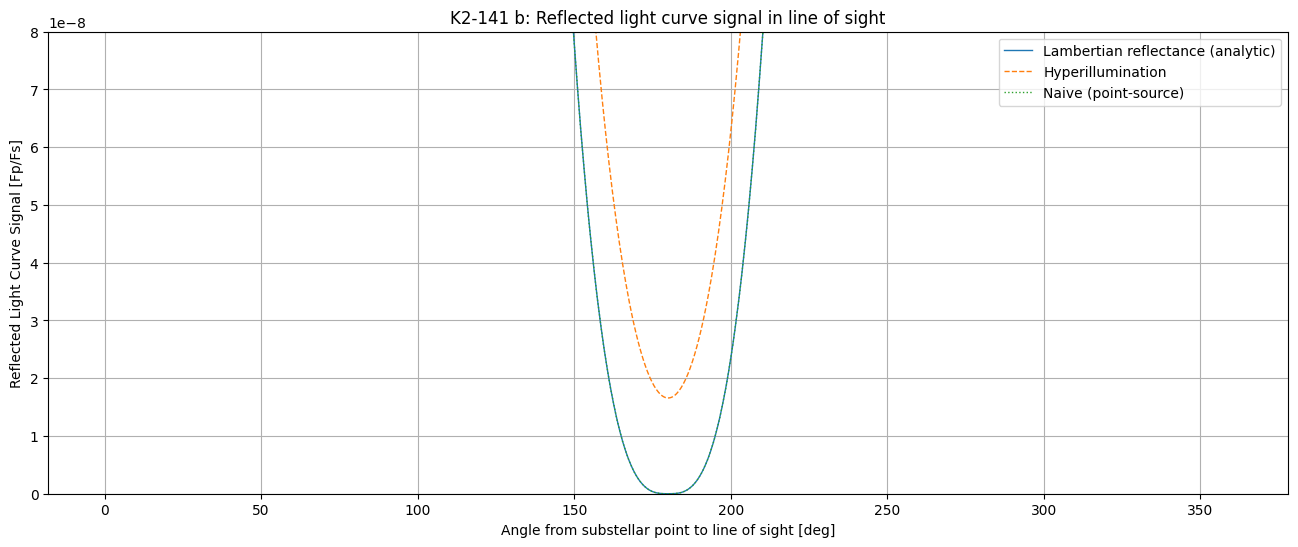

In [7]:
plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_hyperillum, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Light Curve Signal [Fp/Fs]")
plt.title(f"{planet.name}: Reflected light curve signal in line of sight")
plt.legend()
plt.ylim(0., 0.8e-7)
plt.grid()

## Reflected Phase Curve

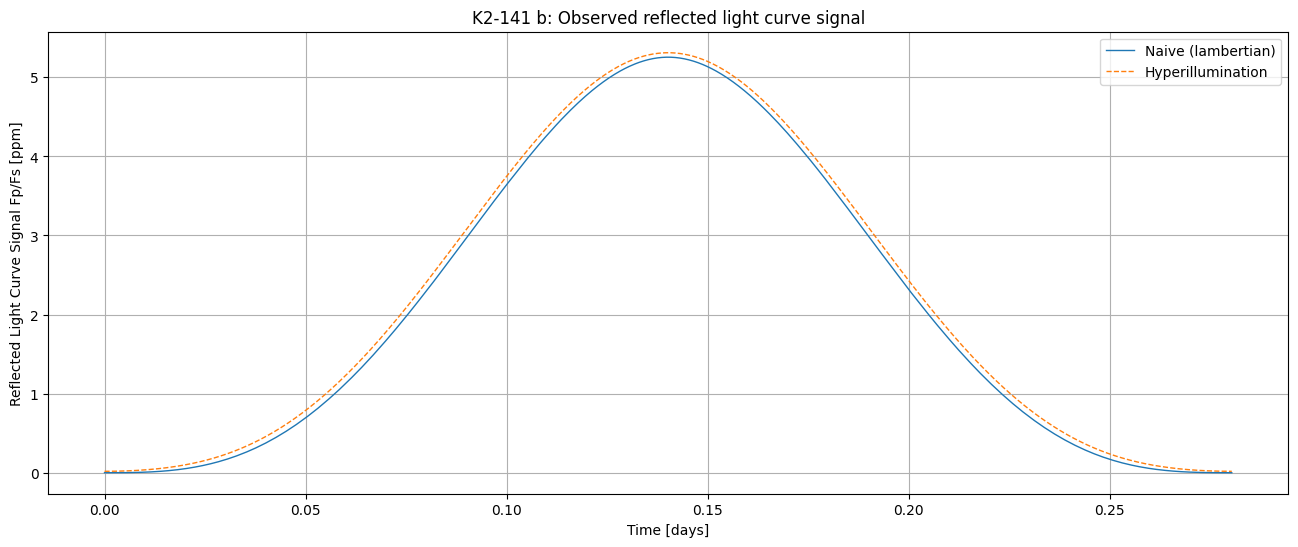

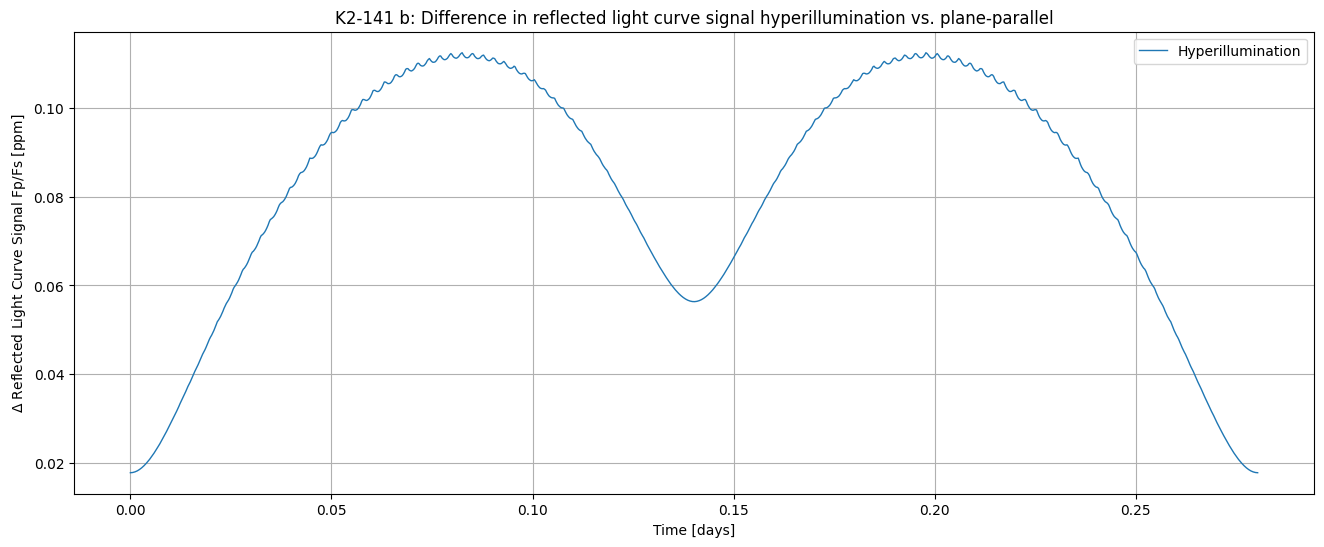

In [8]:
t = np.linspace(0, period, 1000)

orbital_ref_lightcurve_hyperillum = orbital_reflected_lightcurve(t, planet, A=A, u_B=u_B)
orbital_ref_lightcurve_naive = orbital_reflected_lightcurve(t, planet, insolation_model="naive", A=A, u_B=u_B)

plt.figure(figsize=(16, 6))
plt.plot(t, orbital_ref_lightcurve_naive*1e6, linewidth=1, label= "Naive (lambertian)")
plt.plot(t, orbital_ref_lightcurve_hyperillum*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Reflected Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Observed reflected light curve signal")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()

plt.figure(figsize=(16, 6))
plt.plot(t, (orbital_ref_lightcurve_hyperillum-orbital_ref_lightcurve_naive)*1e6, linewidth=1, label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Reflected Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Difference in reflected light curve signal hyperillumination vs. plane-parallel")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()

Wiggles are a numerical artefact in naive light curve signal caused by truncation at 90° (Gauss-Legendre converges exponentially only for smooth integrands). Can be fixed by setting n_phi = 320.

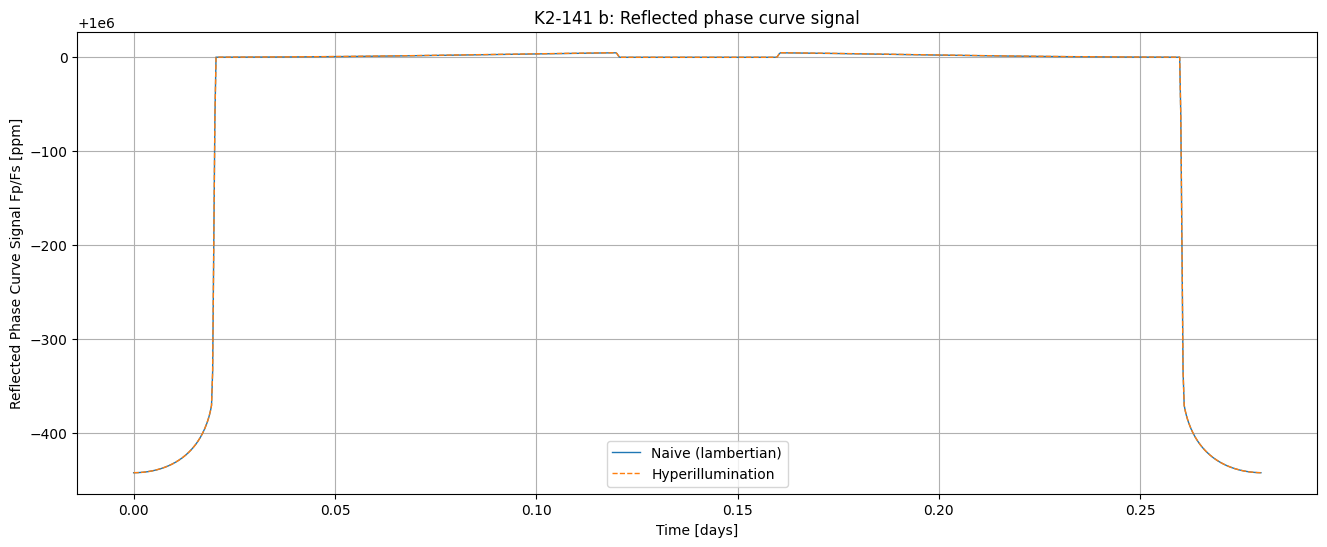

Occultation depth with Hyperillumination: 5.3 ppm   (measured: fp = 142 ppm at 4.5 um)
Occultation depth without Hyperillumination: 5.3 ppm   (measured: fp = 142 ppm at 4.5 um)


In [9]:
t_hyperillum, ref_phasecurve_hyperillum, ref_fp_hyperillum = reflected_PhaseCurve(planet, u=u, A=A, u_B=u_B)
t_naive, ref_phasecurve_naive, ref_fp_naive = reflected_PhaseCurve(planet, u=u, A=A, insolation_model="naive", u_B=u_B)

plt.figure(figsize=(16, 6))
plt.plot(t_naive, ref_phasecurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_hyperillum, ref_phasecurve_hyperillum*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Reflected Phase Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Reflected phase curve signal")
plt.legend()
plt.grid()
plt.show()

print(f"Occultation depth with Hyperillumination: {ref_fp_hyperillum:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")
print(f"Occultation depth without Hyperillumination: {ref_fp_naive:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")

## Consistency Check - Comparison with Spiderman's Lambertian Model

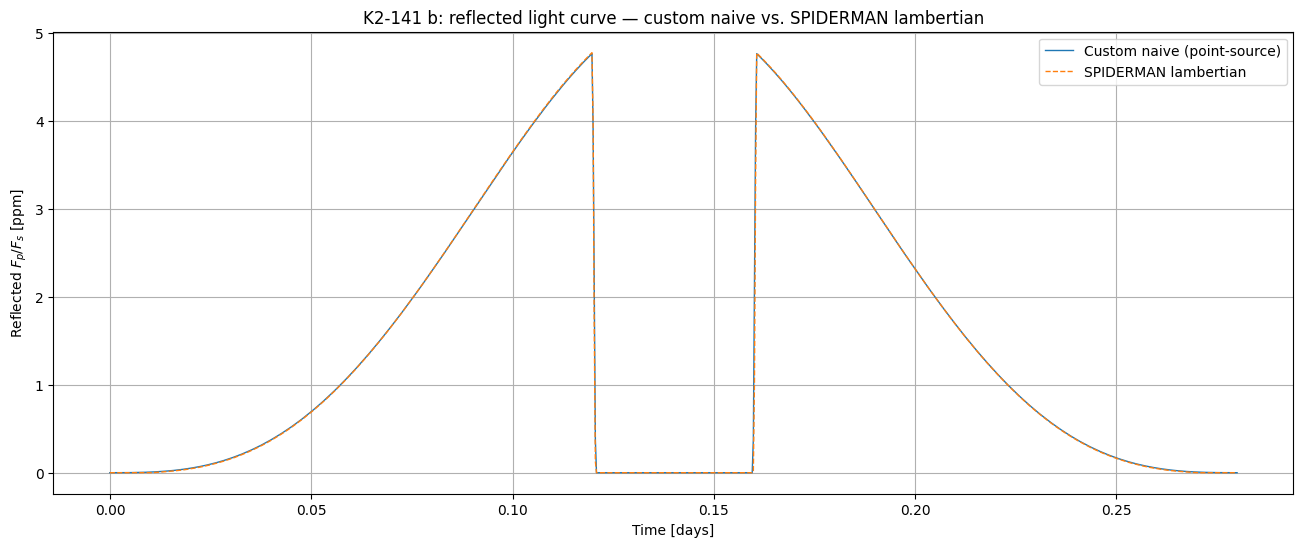

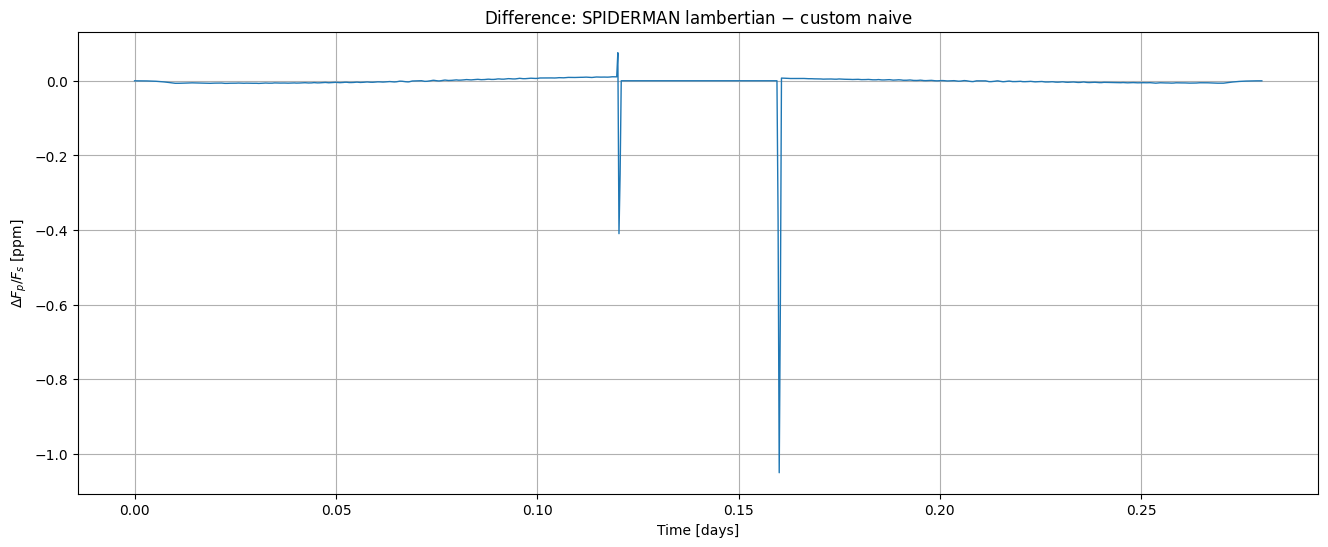

In [10]:
# As expected the Spiderman Lambert model also does not require a wavelength range
sp_lambert = sp.ModelParams(brightness_model="lambertian", stellar_model="blackbody")
sp_lambert.n_layers = 20
sp_lambert.t0, sp_lambert.per = 0., period
sp_lambert.a_abs = a_AU    # semi-major axis [AU]
sp_lambert.inc, sp_lambert.ecc, sp_lambert.w = incl, ecc, w
sp_lambert.rp, sp_lambert.a = rp, a
sp_lambert.p_u1 = sp_lambert.p_u2 = 0.
sp_lambert.eclipse = True
sp_lambert.albedo  = 2/3 * A  # SPIDERMAN albedo ≈ geometric A_g = 2/3·A

t_naive, ref_phasecurve_naive, ref_fp_naive = reflected_PhaseCurve(planet, u=u, A=A, insolation_model="naive", include_transit=False, u_B=u_B)

sp_lambert = sp_lambert.lightcurve(t_naive) - 1.

plt.figure(figsize=(16, 6))
plt.plot(t_naive, ref_phasecurve_naive*1e6,  lw=1, label="Custom naive (point-source)")
plt.plot(t_naive, sp_lambert*1e6, lw=1, ls="--", label="SPIDERMAN lambertian")
plt.xlabel("Time [days]"); plt.ylabel(r"Reflected $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected light curve — custom naive vs. SPIDERMAN lambertian")
plt.legend(); plt.grid(); plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, (sp_lambert - ref_phasecurve_naive)*1e6, lw=1)
plt.xlabel("Time [days]"); plt.ylabel(r"$\Delta F_p/F_s$ [ppm]")
plt.title("Difference: SPIDERMAN lambertian $-$ custom naive"); plt.grid(); plt.show()